In [558]:
import numpy as np
from scipy.optimize import linprog
import matplotlib.pyplot as plt 

zivilo = {} #NA 100 g
zivilo_index = {}
energija = {} #kcal
mascobe = {} #g
oglj_hidr = {} #g
proteini = {} #g
Ca = {} #mg
Fe = {} #mg
vitaminC = {} #mg
kalij = {} #mg
Na = {} #mg
cena = {} #EUR
voda = {} #g
def izrez(podatki):
     for i in range(0,len(podatki)):
        if len(podatki[i]) == 0:
            podatki.remove('')
            return izrez(podatki)
        if i == len(podatki):
            return podatki
i = 0
with open("tabela-zivil.dat") as dat:
    for vrstica in dat:
        podatki = vrstica.split('\t')
        p = izrez(podatki)
        if len(podatki) == 12:
            i += 1
            hrana = podatki[0]
            zivilo[hrana] = 0
            zivilo_index[hrana] = i
            energija[hrana] = float(podatki[1])
            mascobe[hrana] = float(podatki[2])
            oglj_hidr[hrana] = float(podatki[3])
            proteini[hrana] = float(podatki[4])
            value = float(podatki[5]) / 1000
            Ca[hrana] = value
            value = float(podatki[6]) / 1000
            Fe[hrana] = value
            value = float(podatki[7]) / 1000
            vitaminC[hrana] = value
            value = float(podatki[8]) / 1000
            kalij[hrana] = value
            value = float(podatki[9]) / 1000
            Na[hrana] = value
            cena[hrana] = float(podatki[10].replace('\n',''))
            voda[hrana] = float(podatki[11])

VEZI, CENOVNA FUNKCIJA

1. min kalorije

In [559]:
A = [] #matrika koeficientov vezi
logical = [] #oblika (ne)enačbe
b = [] #vektor zahtevanih vrednosti

cenovna = list(energija.values()) #mini/maksi-mizacijski parameter

#vez m <= 2000 g
A.append([100 for i in range(0, len(zivilo))])
logical.append('<')
b.append(2000)
#vez 70 g maščob
A.append(list(mascobe.values()))
logical.append('>')
b.append(70)
#vez 310 g ogljikovih hidratov
A.append(list(oglj_hidr.values()))
logical.append('>')
b.append(310)
#vez 50 g proteinov
A.append(list(proteini.values()))
logical.append('>')
b.append(50)
#vez 1000 mg kalcija
A.append(list(Ca.values()))
logical.append('>')
b.append(1)
#vez 18 mg železa
A.append(list(Fe.values()))
logical.append('>')
b.append(0.018)
#DODATNO
#vez 60  mg vitamina C
A.append(list(vitaminC.values()))
logical.append('>')
b.append(0.06)
#vez 3500 mg kalija
A.append(list(kalij.values()))
logical.append('>')
b.append(3.5)
#vez Na med 500 - 2400 mg
A.append(list(Na.values()))
logical.append('>')
b.append(0.5)
A.append(list(Na.values()))
logical.append('<')
b.append(2.4)

2., 3. min maščobe ali cena dodatna vez

In [610]:
A = [] #matrika koeficientov vezi
logical = [] #oblika (ne)enačbe
b = [] #vektor zahtevanih vrednosti

cenovna = list(mascobe.values()) #mini/maksi-mizacijski parameter

#vez m <= 2000 g
A.append([100 for i in range(0, len(zivilo))])
logical.append('<')
b.append(2000)
#vez 70 g maščob
A.append(list(mascobe.values()))
logical.append('>')
b.append(70)
#vez 310 g ogljikovih hidratov
A.append(list(oglj_hidr.values()))
logical.append('>')
b.append(310)
#vez 50 g proteinov
A.append(list(proteini.values()))
logical.append('>')
b.append(50)
#vez 1000 mg kalcija
A.append(list(Ca.values()))
logical.append('>')
b.append(1)
#vez 18 mg železa
A.append(list(Fe.values()))
logical.append('>')
b.append(0.018)
#DODATNO
#vez 60  mg vitamina C
A.append(list(vitaminC.values()))
logical.append('>')
b.append(0.06)
#vez 3500 mg kalija
A.append(list(kalij.values()))
logical.append('>')
b.append(3.5)
#vez Na med 500 - 2400 mg
A.append(list(Na.values()))
logical.append('>')
b.append(0.5)
A.append(list(Na.values()))
logical.append('<')
b.append(2.4)
# vez min 2000 kcal
A.append(list(energija.values()))
logical.append('>')
b.append(2000)
# vez min 1 l vode - 1000 g
A.append(list(voda.values()))
logical.append('>')
b.append(1000)

In [611]:
A = np.array(A)
b = np.array(b)
#pretvorba v neenakost tipa <
for i in range(0, len(b)):
    if logical[i] == '>':
        b[i] = (-1) * b[i]
        A[i][::] = (-1) * A[i][::]
        logical[i] = '<'

4. omejitev količine živila

In [612]:
max_kol = 300 #g
omejitev = [(0, max_kol/100) for i in range(0, len(cenovna))]
res = linprog(cenovna, A_ub=A, b_ub=b, bounds=omejitev) #omejena količina za vse
res = linprog(cenovna, A_ub=A, b_ub=b)
vrednost_optimum = res.fun
zivilo.update(zip(zivilo, res.x))

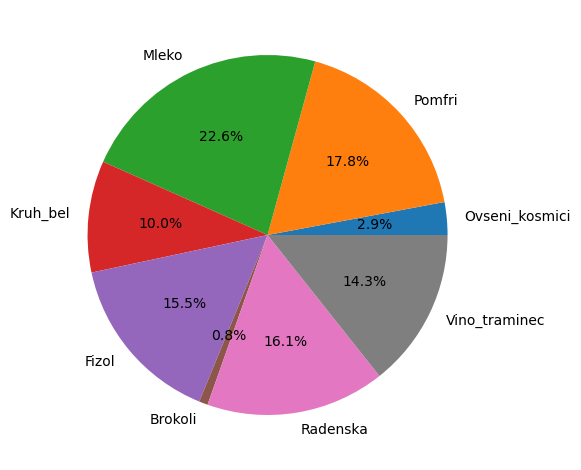

(2000.0, 70.0)

In [613]:
zivila_prikaz = []
neuporabljena = []
vrednosti_prikaz = []
for i in range(0, len(list(zivilo.values()))):
    if list(zivilo.values())[i] != 0:
        zivila_prikaz.append(list(zivilo.keys())[i])
        vrednosti_prikaz.append(list(zivilo.values())[i])
    else:
        neuporabljena.append(list(zivilo.keys())[i])
skupna_masa = sum(vrednosti_prikaz)*100
plt.pie(vrednosti_prikaz, labels=zivila_prikaz, autopct='%1.1f%%')
plt.tight_layout()
#plt.savefig('slike/brez_vez_vode.pdf')
plt.show()
skupna_masa, vrednost_optimum

In [614]:
for i in range(0, len(zivila_prikaz)):
    print(zivila_prikaz[i], ':', int(vrednosti_prikaz[i]*100), ' g')

Ovseni_kosmici : 58  g
Pomfri : 355  g
Mleko : 452  g
Kruh_bel : 200  g
Fizol : 309  g
Brokoli : 15  g
Radenska : 321  g
Vino_traminec : 286  g


In [615]:
print('Uporabljenih živil = ', len(zivila_prikaz) / len(zivilo) * 100, ' %')
print('NEuporabljenih živil = ', len(neuporabljena) / len(zivilo) * 100, ' %')


Uporabljenih živil =  16.3265306122449  %
NEuporabljenih živil =  83.6734693877551  %


In [616]:
energija_sk = sum([list(zivilo.values())[i] * list(energija.values())[i] for i in range(0, len(zivilo.values()))])
print('energija', energija_sk, 'kcal')
maščobe_sk = sum([list(zivilo.values())[i] * list(mascobe.values())[i] for i in range(0, len(zivilo.values()))])
print('maščobe', maščobe_sk, 'g')
oglj_hidr_sk = sum([list(zivilo.values())[i] * list(oglj_hidr.values())[i] for i in range(0, len(zivilo.values()))])
print('ogljikovi hidrati', oglj_hidr_sk, 'g')
proteini_sk = sum([list(zivilo.values())[i] * list(proteini.values())[i] for i in range(0, len(zivilo.values()))])
print('proteini', proteini_sk, 'g')
Ca_sk = sum([list(zivilo.values())[i] * list(Ca.values())[i] for i in range(0, len(zivilo.values()))])
print('kalcij', Ca_sk, 'mg')
Fe_sk = sum([list(zivilo.values())[i] * list(Fe.values())[i] for i in range(0, len(zivilo.values()))])
print('železo', Fe_sk, 'mg')
vitaminC_sk = sum([list(zivilo.values())[i] * list(vitaminC.values())[i] for i in range(0, len(zivilo.values()))])
print('vitamin C', vitaminC_sk, 'mg')
kalij_sk = sum([list(zivilo.values())[i] * list(kalij.values())[i] for i in range(0, len(zivilo.values()))])
print('kalij', kalij_sk, 'mg')
Na_sk = sum([list(zivilo.values())[i] * list(Na.values())[i] for i in range(0, len(zivilo.values()))])
print('natrij', Na_sk, 'mg')
cena_sk = sum([list(zivilo.values())[i] * list(cena.values())[i] for i in range(0, len(zivilo.values()))])
print('cena ', cena_sk, 'EUR')
print('masa', skupna_masa)
print('število živil', len(zivila_prikaz))

energija 1999.9999999999998 kcal
maščobe 70.0 g
ogljikovi hidrati 311.6627709090244 g
proteini 80.52001112878996 g
kalcij 1.0000000000000002 mg
železo 0.018 mg
vitamin C 0.06 mg
kalij 3.651690635580905 mg
natrij 2.4 mg
cena  5.08117196384767 EUR
masa 2000.0
število živil 8


In [617]:
for i in range(0, len(zivilo.values())):
    if list(zivilo.values())[i] != 0:
        print(list(zivilo.keys())[i], list(zivilo.values())[i] * list(cena.values())[i])

Ovseni_kosmici 0.06456499644506127
Pomfri 0.3558981638030955
Mleko 0.4520590265975979
Kruh_bel 0.3405756578366519
Fizol 1.0819523132516728
Brokoli 0.04723438718169305
Radenska 0.16084264428019293
Vino_traminec 2.5780447744517048


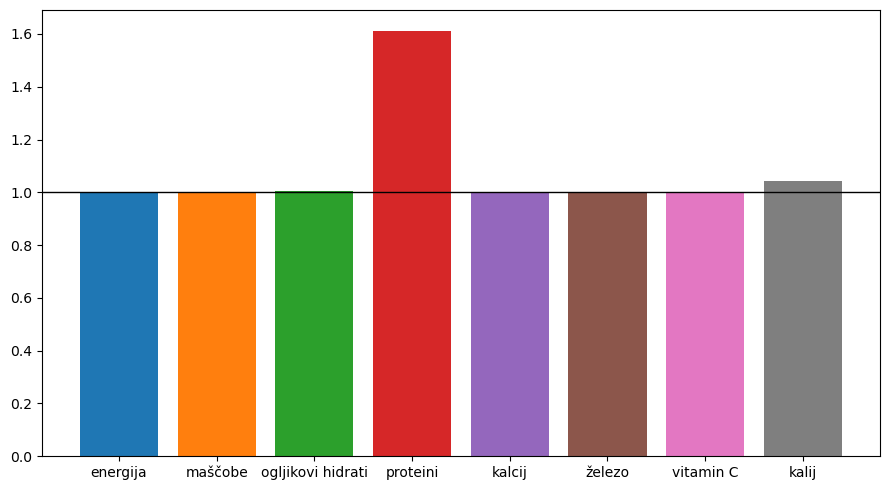

In [618]:
plt.figure(figsize=(9,5))
plt.axhline(y=1, color='k', linewidth=1)
plt.bar('energija', energija_sk/2000)
plt.bar('maščobe', maščobe_sk/70)
plt.bar('ogljikovi hidrati', oglj_hidr_sk/310)
plt.bar('proteini', proteini_sk/50)
plt.bar('kalcij', Ca_sk/1)
plt.bar('železo', Fe_sk/0.018)
plt.bar('vitamin C', vitaminC_sk/0.06)
plt.bar('kalij', kalij_sk/3.5)
#plt.bar('natrij', Na_sk/0.5) #min
#plt.bar('natrij', Na_sk/2.4) #max - težko merljivo!
plt.tight_layout()
#plt.savefig('slike/3.primer_vezi.pdf')
plt.show()

omejitev - rezultati

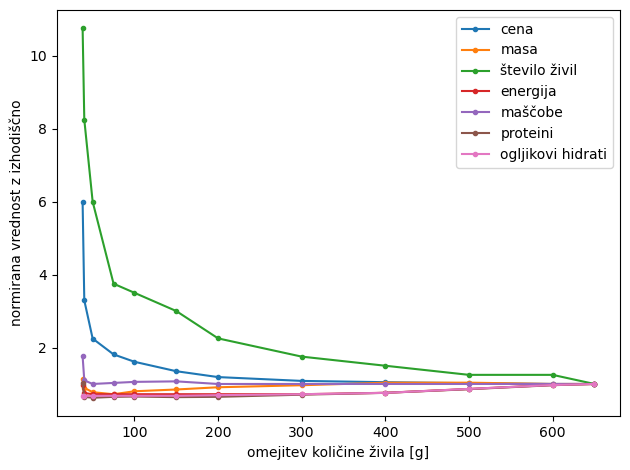

In [619]:
omejitev_ = np.array([650, 600, 500, 400, 300, 200, 150, 100, 75, 50, 40, 38])
cena_ = np.array([1.43, 1.43, 1.46, 1.50, 1.55, 1.70, 1.93, 2.30, 2.59, 3.21, 4.71, 8.55])
masa_ = np.array([1405, 1405, 1455, 1454, 1356, 1278, 1192, 1124, 1010, 1088, 1256, 1594])
št_živil_ = np.array([4, 5, 5, 6, 7, 9, 12, 14, 15, 24, 33, 43])
energija_ = np.array([2782, 2705, 2400, 2109, 2000, 2000, 2000, 2000, 2000, 2000, 2089, 2717])
maščobe_ = np.array([70, 70, 70, 70, 70, 70, 75, 74, 72, 70, 77, 123])
proteini_ = np.array([119, 115, 102, 90, 84, 77, 76, 78, 77, 74, 77, 121])
oglj_hidr_ = np.array([459, 446, 397, 347, 330, 318, 310, 310, 310, 310, 310, 312])

podatki = [cena_/cena_[0], masa_/masa_[0], št_živil_/št_živil_[0], energija_/energija_[0], maščobe_/maščobe_[0], proteini_/proteini_[0], oglj_hidr_/oglj_hidr_[0]]
label = ['cena', 'masa', 'število živil', 'energija', 'maščobe', 'proteini', 'ogljikovi hidrati']
for (i,l) in zip(podatki, label):
    plt.plot(omejitev_, i, '.-', label=l)
plt.legend()
plt.xlabel('omejitev količine živila [g]')
plt.ylabel('normirana vrednost z izhodiščno')
plt.tight_layout()
#plt.savefig('slike/vpliv_omejitve_zivil.pdf')
plt.show()